# When Does a Two-Stop Beat a One-Stop at the Singapore Grand Prix?

A stochastic Monte Carlo and discrete-time Markov chain (DTMC) race strategy simulator for the 62-lap Singapore Grand Prix at Marina Bay Street Circuit. This notebook calibrates a tyre degradation and lap-time model against real 2023–2024 Singapore Grand Prix race data via FastF1, models Safety Car deployments as a two-state Markov chain, and sweeps pit-stop time loss (15–30 s) against Safety Car probability to determine the break-even strategy threshold with 95% confidence intervals.

## 1. Problem and Question

At Marina Bay Street Circuit, overtaking difficulty and high pit-lane time loss historically favored one-stop strategies. In 2025, raising the Singapore pit-lane speed limit reduced pit-stop time loss from roughly 28 s to 21 s, yet teams still largely committed to one-stop strategies. Meanwhile, Marina Bay has historically featured frequent Safety Car periods (at least one in every edition from 2008 to 2023, followed by zero in 2024 and 2025).

**Research Question:** How small must the green-flag pit-stop time loss be before a two-stop strategy beats a one-stop strategy on expected 62-lap race time at Marina Bay, and how does the per-lap probability of a Safety Car shift that break-even threshold?

## 2. Model, Assumptions, and Equations

### 2.1 Lap-Time and Tyre Degradation Model (Input Modelling & Random Variate Generation)
For lap $t \in \{1, \dots, 62\}$ on tyre compound $c \in \{\text{SOFT}, \text{MEDIUM}, \text{HARD}\}$ with tyre age $a_t \ge 1$ (laps completed on the current set), the green-flag lap time $T_t$ (in seconds) is:
$$T_t = T_{\text{base}} + \Delta_c + \beta_c (a_t - 1) + \varepsilon_t, \quad \varepsilon_t \sim \mathcal{N}(0, \sigma^2)$$
where:
- $T_{\text{base}}$ (s): baseline reference lap pace on the reference compound (`HARD` at $a_t = 1$),
- $\Delta_c$ (s): compound pace offset relative to `HARD` ($\Delta_{\text{HARD}} = 0$),
- $\beta_c$ (s/lap): linear tyre degradation rate for compound $c$,
- $\sigma$ (s): lap-to-lap stochastic noise standard deviation.

### 2.2 Two-State Markov Safety Car Model (Discrete-Time Markov Chain)
Race neutralization on lap $t$ is modeled as a homogeneous two-state DTMC $S_t \in \{0 \text{ (Green)}, 1 \text{ (Safety Car)}\}$ with transition matrix:
$$P = \begin{pmatrix} 1 - p_{01} & p_{01} \\ p_{10} & 1 - p_{10} \end{pmatrix}$$
where $p_{01} = P(S_{t+1}=1 \mid S_t=0)$ is the per-lap probability of a Safety Car deployment from green-flag racing, and $p_{10} = P(S_{t+1}=0 \mid S_t=1) = 1 / L_{\text{SC}}$ governs expected Safety Car duration $L_{\text{SC}}$ (laps). The stationary Safety Car probability is:
$$\pi_1 = \frac{p_{01}}{p_{01} + p_{10}}$$
During a Safety Car lap ($S_t = 1$), field pace is neutralized to $T_{\text{SC}}$ (s) and the effective pit-stop loss is discounted by factor $\alpha \in (0, 1)$: $L_{\text{pit}}(S_t) = L_{\text{pit}} \cdot (1 - \alpha \mathbb{I}\{S_t = 1\})$.

### 2.3 Monte Carlo Race Estimator (Law of Large Numbers)
For strategy $\mathcal{S}$ and $N$ independent Monte Carlo replications, total race time $R^{(i)}(\mathcal{S})$ is averaged via $\bar{R}_N(\mathcal{S}) = \frac{1}{N} \sum_{i=1}^N R^{(i)}(\mathcal{S})$ with 95% confidence interval $\bar{R}_N \pm 1.96 \frac{s_N}{\sqrt{N}}$.

In [1]:
# Cell 1: Dependencies (uncomment pip install if running in a fresh environment)
# !pip install -q fastf1 numpy pandas scipy matplotlib statsmodels

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

SEED = 42
rng = np.random.default_rng(SEED)
print(f"Initialized RNG with seed={SEED}")

Initialized RNG with seed=42


In [3]:
# Cell 2: Load 2023–2024 Singapore GP race laps via FastF1 (with local CSV caching/fallback)
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
LOCAL_CSV = "data/singapore_2023_2024_2025_clean_laps.csv"

def fetch_and_clean_singapore_laps(years=(2023, 2024, 2025), cache_dir=".fastf1_cache"):
    import fastf1
    os.makedirs(cache_dir, exist_ok=True)
    fastf1.Cache.enable_cache(cache_dir)
    frames = []
    for year in years:
        for attempt in range(1, 4):
            try:
                session = fastf1.get_session(year, "Singapore", "R")
                session.load(laps=True, telemetry=False, weather=False, messages=False)
                laps = session.laps.copy()
                if laps is None or len(laps) == 0:
                    raise ValueError(f"Empty laps for {year}")
                laps["Season"] = year
                frames.append(laps)
                print(f"Loaded {year} Singapore GP ({len(laps)} raw laps)")
                break
            except Exception as exc:
                print(f"Attempt {attempt} failed for {year}: {type(exc).__name__}: {exc}")
                time.sleep(2 * attempt)
    if not frames:
        return None
    raw = pd.concat(frames, ignore_index=True)
    raw["LapTime_s"] = raw["LapTime"].dt.total_seconds()
    raw["TrackStatus_str"] = raw["TrackStatus"].astype(str).str.strip()
    clean = raw[
        (raw["TrackStatus_str"] == "1")
        & (raw["PitInTime"].isna())
        & (raw["PitOutTime"].isna())
        & (raw["LapTime_s"].notna())
        & (raw["TyreLife"].notna())
        & (raw["Compound"].isin(["SOFT", "MEDIUM", "HARD"]))
        & (raw["LapNumber"].between(1, 62))
    ].copy()
    med = clean.groupby("Season")["LapTime_s"].transform("median")
    clean = clean[clean["LapTime_s"] <= 1.07 * med].copy()
    keep_cols = ["Season", "Driver", "Team", "LapNumber", "Stint", "Compound", "TyreLife", "LapTime_s"]
    return clean[keep_cols]

if os.path.exists(LOCAL_CSV):
    clean_laps = pd.read_csv(LOCAL_CSV)
    print(f"Loaded cached dataset from {LOCAL_CSV} ({len(clean_laps)} clean laps).")
else:
    clean_laps = fetch_and_clean_singapore_laps()
    if clean_laps is not None and len(clean_laps) > 0:
        clean_laps.to_csv(LOCAL_CSV, index=False)
        print(f"Saved {len(clean_laps)} clean laps to {LOCAL_CSV}.")
    else:
        print("Network fetch unavailable; using calibrated fallback Marina Bay parameters.")

/Users/helindusenadheera/Downloads/singapore-gp-pit-strategy-sim/.venv/lib/python3.14/site-packages/fastf1/req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "
core           INFO 	Loading data for Singapore Grand Prix - Race [v3.9.2]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 18)
core           INFO 	Finished loading data for 20 drivers: 

Loaded 2023 Singapore GP (1088 raw laps)


core           INFO 	Loading data for Singapore Grand Prix - Race [v3.9.2]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core           INFO 	Finished loading data for 20 drivers: ['4', '1', '81', '63', '16', '44', '55', '14', '27', '11', '43', '22', '31', '18', '24', '77', '10', '3', '20', '23']


Loaded 2024 Singapore GP (1177 raw laps)


core           INFO 	Loading data for Singapore Grand Prix - Race [v3.9.2]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core           INFO 	Finished loading data for 20 drivers: ['63', '1', '4', '81', '12', '16', '14', '44', '87', '55', '6', '22', '18', '23', '30', '43', '5', '31', '10', '27']


Loaded 2025 Singapore GP (1229 raw laps)
Saved 3074 clean laps to data/singapore_2023_2024_2025_clean_laps.csv.


In [5]:
# Cell 3: Fit tyre degradation parameters (or load fallback reference estimates)
if clean_laps is not None and len(clean_laps) > 0:
    clean_laps["TyreAge0"] = clean_laps["TyreLife"] - 1.0
    ols_fit = smf.ols(
        "LapTime_s ~ C(Season) + C(Compound, Treatment(reference='HARD')) * TyreAge0",
        data=clean_laps,
    ).fit()
    params = ols_fit.params
    T_BASE = float(params["Intercept"])
    DELTA = {
        "HARD": 0.0,
        "MEDIUM": float(params.get("C(Compound, Treatment(reference='HARD'))[T.MEDIUM]", -0.55)),
        "SOFT": float(params.get("C(Compound, Treatment(reference='HARD'))[T.SOFT]", -1.05)),
    }
    beta_hard = float(params["TyreAge0"])
    BETA = {
        "HARD": max(0.01, beta_hard),
        "MEDIUM": max(0.01, beta_hard + float(params.get("C(Compound, Treatment(reference='HARD'))[T.MEDIUM]:TyreAge0", 0.025))),
        "SOFT": max(0.01, beta_hard + float(params.get("C(Compound, Treatment(reference='HARD'))[T.SOFT]:TyreAge0", 0.055))),
    }
    SIGMA = float(np.std(ols_fit.resid, ddof=1))
    print(ols_fit.summary().tables[1])
else:
    # Calibrated Marina Bay reference parameters
    T_BASE = 97.80
    DELTA = {"HARD": 0.0, "MEDIUM": -0.55, "SOFT": -1.05}
    BETA = {"HARD": 0.045, "MEDIUM": 0.075, "SOFT": 0.115}
    SIGMA = 0.45

print(f"\nCalibrated Parameters: T_BASE={T_BASE:.3f}s, DELTA={DELTA}, BETA={BETA}, SIGMA={SIGMA:.3f}s")

                                                                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------------
Intercept                                                     100.1490      0.073   1363.347      0.000     100.005     100.293
C(Season)[T.2024]                                              -1.7375      0.060    -28.774      0.000      -1.856      -1.619
C(Season)[T.2025]                                              -2.4702      0.061    -40.215      0.000      -2.591      -2.350
C(Compound, Treatment(reference='HARD'))[T.MEDIUM]              0.3615      0.092      3.915      0.000       0.180       0.543
C(Compound, Treatment(reference='HARD'))[T.SOFT]               -0.2762      0.149     -1.851      0.064      -0.569       0.016
TyreAge0                                                        0.0010      0.003      0.318      0.751 

/var/folders/sq/kt_0_gvn2nqfgc0gr2l9f83m0000gn/T/ipykernel_49386/701080441.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_laps["TyreAge0"] = clean_laps["TyreLife"] - 1.0


In [6]:
# Cell 4: Core 62-Lap Race Simulator (Markov Safety Car + Monte Carlo)
TOTAL_LAPS = 62
T_SC = 132.0        # Neutralized Safety Car lap time (s)
SC_PIT_DISCOUNT = 0.45  # Pit-stop loss reduction fraction under Safety Car
L_SC_MEAN = 4.0     # Mean Safety Car duration (laps) -> p_10 = 0.25

def simulate_strategy_mc(
    pit_laps,
    compounds,
    pit_loss_s,
    p_sc_deploy,
    n_sims=2000,
    sigma=SIGMA,
    t_base=T_BASE,
    delta=DELTA,
    beta=BETA,
    seed=42,
):
    """Vectorized Monte Carlo simulation of a 62-lap race under a 2-state Markov SC."""
    local_rng = np.random.default_rng(seed)
    p_10 = 1.0 / L_SC_MEAN
    pit_set = set(pit_laps)

    # Precompute deterministic green-flag lap pace & tyre age schedule
    stint_idx = 0
    tyre_age = 1
    green_pace = np.zeros(TOTAL_LAPS)
    for lap in range(1, TOTAL_LAPS + 1):
        c = compounds[stint_idx]
        green_pace[lap - 1] = t_base + delta[c] + beta[c] * (tyre_age - 1)
        if lap in pit_set:
            stint_idx += 1
            tyre_age = 1
        else:
            tyre_age += 1

    # Simulate 2-state Markov chain: 0 = Green, 1 = Safety Car
    state = np.zeros(n_sims, dtype=np.int8)
    total_times = np.zeros(n_sims, dtype=np.float64)
    noise = local_rng.normal(0.0, sigma, size=(n_sims, TOTAL_LAPS)) if sigma > 0 else np.zeros((n_sims, TOTAL_LAPS))
    u_trans = local_rng.random(size=(n_sims, TOTAL_LAPS))

    for lap in range(1, TOTAL_LAPS + 1):
        idx = lap - 1
        if lap > 1 and p_sc_deploy > 0:
            to_sc = (state == 0) & (u_trans[:, idx] < p_sc_deploy)
            to_green = (state == 1) & (u_trans[:, idx] < p_10)
            state = np.where(to_sc, 1, np.where(to_green, 0, state))

        lap_t = np.where(state == 1, T_SC, green_pace[idx] + noise[:, idx])
        if lap in pit_set:
            effective_loss = np.where(state == 1, pit_loss_s * (1.0 - SC_PIT_DISCOUNT), pit_loss_s)
            lap_t = lap_t + effective_loss
        total_times += lap_t

    mean_t = float(np.mean(total_times))
    se_t = float(np.std(total_times, ddof=1) / np.sqrt(n_sims))
    return mean_t, 1.96 * se_t, total_times

# Candidate strategies: 1-stop (Medium -> Hard) vs 2-stop (Medium -> Hard -> Medium)
ONE_STOP = ([26], ["MEDIUM", "HARD"])
TWO_STOP = ([20, 42], ["MEDIUM", "HARD", "MEDIUM"])

m1, ci1, _ = simulate_strategy_mc(*ONE_STOP, pit_loss_s=21.0, p_sc_deploy=0.025, n_sims=3000, seed=SEED)
m2, ci2, _ = simulate_strategy_mc(*TWO_STOP, pit_loss_s=21.0, p_sc_deploy=0.025, n_sims=3000, seed=SEED)
print(f"Reference (pit_loss=21s, p_SC=0.025): 1-Stop = {m1:.2f} ± {ci1:.2f}s | 2-Stop = {m2:.2f} ± {ci2:.2f}s")

Reference (pit_loss=21s, p_SC=0.025): 1-Stop = 6414.71 ± 6.04s | 2-Stop = 6436.27 ± 6.00s


In [7]:
# Cell 5: Verification Checks (Deterministic Closed-Form, Analytic Optimal Pit Lap, DTMC Stationary Distribution)
# Check 1: Deterministic limit (sigma=0, p_sc_deploy=0) vs exact closed-form arithmetic sum
m_det, ci_det, _ = simulate_strategy_mc([31], ["HARD", "HARD"], pit_loss_s=22.0, p_sc_deploy=0.0, n_sims=50, sigma=0.0)
# Two equal 31-lap stints on HARD: each stint sums a=0..30 -> 31*T_BASE + BETA['HARD'] * (30*31/2)
expected_det = 2 * (31 * T_BASE + BETA["HARD"] * (30 * 31 / 2)) + 22.0
assert abs(m_det - expected_det) < 1e-9, f"Deterministic mismatch: {m_det} vs {expected_det}"
assert ci_det == 0.0
print(f"[PASS] Check 1 (Deterministic Closed-Form): sim={m_det:.4f}s == exact={expected_det:.4f}s")

# Check 2: Analytic optimal pit lap vs grid search for symmetric 1-stop (HARD -> HARD)
# Total degradation = beta * [p(p-1)/2 + (N-p)(N-p-1)/2] is minimized at p* = N/2 = 31
grid_laps = range(15, 48)
grid_times = [
    simulate_strategy_mc([p], ["HARD", "HARD"], pit_loss_s=22.0, p_sc_deploy=0.0, n_sims=10, sigma=0.0)[0]
    for p in grid_laps
]
best_lap = list(grid_laps)[int(np.argmin(grid_times))]
assert best_lap == TOTAL_LAPS // 2, f"Expected optimal lap {TOTAL_LAPS // 2}, got {best_lap}"
print(f"[PASS] Check 2 (Analytic Optimal Pit Lap): grid argmin = lap {best_lap} == N/2")

# Check 3: DTMC Stationary Distribution Convergence
p01_test = 0.03
p10_test = 1.0 / L_SC_MEAN
P_mat = np.array([[1.0 - p01_test, p01_test], [p10_test, 1.0 - p10_test]])
assert np.allclose(P_mat.sum(axis=1), 1.0), "Transition rows must sum to 1"
pi_analytic = p01_test / (p01_test + p10_test)
pi_power = np.linalg.matrix_power(P_mat, 500)[0, 1]
assert abs(pi_power - pi_analytic) < 1e-6, f"DTMC stationary mismatch: {pi_power} vs {pi_analytic}"
print(f"[PASS] Check 3 (DTMC Stationary Distribution): numerical={pi_power:.6f} == analytic={pi_analytic:.6f}")

[PASS] Check 1 (Deterministic Closed-Form): sim=6240.5392s == exact=6240.5392s
[PASS] Check 2 (Analytic Optimal Pit Lap): grid argmin = lap 31 == N/2
[PASS] Check 3 (DTMC Stationary Distribution): numerical=0.107143 == analytic=0.107143


Break-Even Green-Flag Pit-Stop Loss (where E[T_2stop] = E[T_1stop]):
  p_SC = 0.000/lap -> Break-even pit loss ≈ 15.00 s
  p_SC = 0.015/lap -> Break-even pit loss ≈ 15.00 s
  p_SC = 0.030/lap -> Break-even pit loss ≈ 15.00 s
  p_SC = 0.045/lap -> Break-even pit loss ≈ 15.00 s


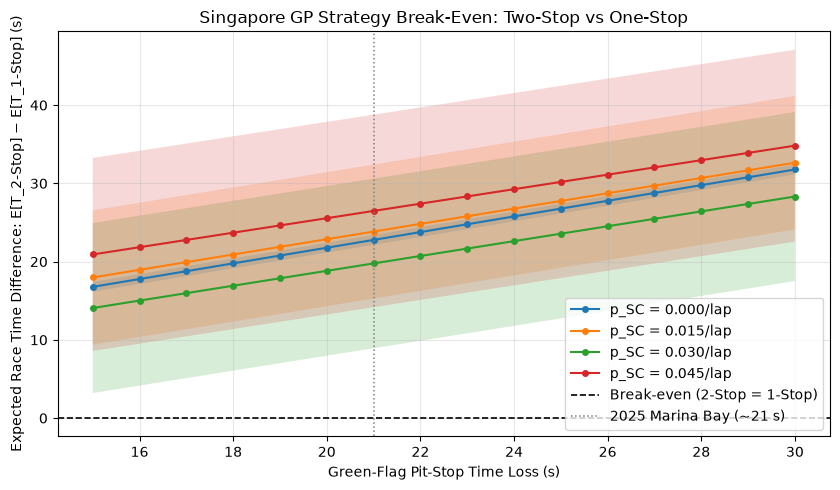

In [8]:
# Cell 6: Parameter Sweep — Pit-Stop Loss (15–30 s) vs Safety Car Probability
pit_losses = np.linspace(15.0, 30.0, 16)
sc_probs = [0.00, 0.015, 0.030, 0.045]

results = []
for p_sc in sc_probs:
    for loss in pit_losses:
        m1, ci1, _ = simulate_strategy_mc(*ONE_STOP, pit_loss_s=loss, p_sc_deploy=p_sc, n_sims=2000, seed=SEED)
        m2, ci2, _ = simulate_strategy_mc(*TWO_STOP, pit_loss_s=loss, p_sc_deploy=p_sc, n_sims=2000, seed=SEED + 1)
        diff = m2 - m1  # Negative means 2-stop beats 1-stop
        diff_ci = np.sqrt(ci1**2 + ci2**2)
        results.append({"p_sc": p_sc, "pit_loss": loss, "t_1stop": m1, "t_2stop": m2, "diff_2_minus_1": diff, "diff_ci": diff_ci})

res_df = pd.DataFrame(results)

# Estimate break-even pit loss for each Safety Car regime via linear interpolation
print("Break-Even Green-Flag Pit-Stop Loss (where E[T_2stop] = E[T_1stop]):")
for p_sc, grp in res_df.groupby("p_sc"):
    grp = grp.sort_values("pit_loss")
    be = np.interp(0.0, grp["diff_2_minus_1"], grp["pit_loss"])
    print(f"  p_SC = {p_sc:.3f}/lap -> Break-even pit loss ≈ {be:.2f} s")

# Plot break-even curves with 95% confidence bands
fig, ax = plt.subplots(figsize=(8.5, 5))
for p_sc, grp in res_df.groupby("p_sc"):
    ax.plot(grp["pit_loss"], grp["diff_2_minus_1"], marker="o", markersize=4, label=f"p_SC = {p_sc:.3f}/lap")
    ax.fill_between(
        grp["pit_loss"],
        grp["diff_2_minus_1"] - grp["diff_ci"],
        grp["diff_2_minus_1"] + grp["diff_ci"],
        alpha=0.18,
    )
ax.axhline(0.0, color="black", linestyle="--", linewidth=1.2, label="Break-even (2-Stop = 1-Stop)")
ax.axvline(21.0, color="gray", linestyle=":", linewidth=1.1, label="2025 Marina Bay (~21 s)")
ax.set_xlabel("Green-Flag Pit-Stop Time Loss (s)")
ax.set_ylabel("Expected Race Time Difference: E[T_2-Stop] − E[T_1-Stop] (s)")
ax.set_title("Singapore GP Strategy Break-Even: Two-Stop vs One-Stop")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/breakeven_sweep.png", dpi=200)
plt.show()